# Micro proyecto 2: Generación de código Python con Transformers

**Universidad de los Andes** · Maestría en Inteligencia Artificial (MAIA)
**Curso:** Modelos Avanzados para el Procesamiento de Lenguaje Natural
**Equipo:** MP1 Equipo 21

| Integrantes |
|---|
| Juan Javier Valera Mejías |
| Juan David Villalba Guavita |
| Juan Felipe Rodríguez Granados |
| Leidy Dayana Vega Medina |
| Cesar Steven Leal Pérez |

## 1. Portada e introducción

En este proyecto entrenamos modelos de lenguaje tipo decoder-only para completar código Python, usando el dataset `codeparrot/codeparrot-clean`. Tomamos 8.000 archivos de entre 1.000 y 2.000 caracteres y los dividimos en 6.400 para entrenamiento, 800 para validación y 800 para prueba. Todos los modelos usan el tokenizador de SmolLM2 (49.152 tokens) y secuencias de 256 tokens, así que las perplejidades se pueden comparar directamente.

Comparamos cinco configuraciones:

| # | Configuración | Entrenamiento |
|---|---|---|
| 1 | GPT desde cero | Implementado en PyTorch (6 bloques, dimensión 512, 8 cabezas), entrenado solo con este corpus |
| 2 | SmolLM2-135M pre-entrenado | Ninguno (baseline) |
| 3 | SmolLM2-135M finetuned | Finetuning completo |
| 4 | SmolLM2-360M pre-entrenado | Ninguno (baseline) |
| 5 | SmolLM2-360M finetuned | Finetuning completo |

Los tres modelos que entrenamos usan el mismo ciclo de entrenamiento: AdamW con warmup y decaimiento coseno, precisión mixta y acumulación de gradiente (en los SmolLM2 también gradient checkpointing). Durante el entrenamiento se evalúa en validación varias veces por época y se guarda el mejor estado, que es el que se evalúa en prueba.

La métrica principal es la perplejidad por token en el conjunto de prueba. Como métrica secundaria medimos el porcentaje de completaciones que `ast.parse` acepta, sobre 200 archivos de prueba. La generación se hace con una función propia (sin `model.generate()`) que se usa igual para los cinco modelos.

El notebook se ejecutó en Google Colab con GPU T4. Los checkpoints se guardan en Google Drive; si ya existen, se cargan en vez de volver a entrenar.

## 2. Librerías

In [1]:
import os, sys, ast, gc, json, math, time, random, shutil, contextlib
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

import datasets
import transformers
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM
from IPython.display import display, Markdown

transformers.logging.set_verbosity_error()
datasets.logging.set_verbosity_error()

print(f'Python {sys.version.split()[0]} | torch {torch.__version__} | transformers {transformers.__version__} | datasets {datasets.__version__}')

Python 3.13.16 | torch 2.11.0+cu130 | transformers 5.21.0 | datasets 4.8.5


In [2]:
SEMILLA = 21
DATASET = 'codeparrot/codeparrot-clean'
MIN_CARACTERES, MAX_CARACTERES = 1000, 2000
N_TOTAL, N_TRAIN, N_VAL, N_TEST = 8000, 6400, 800, 800
CONTEXTO = 256
N_VALIDEZ = 200
TOKENS_PROMPT_VALIDEZ = 64
TOKENS_NUEVOS_VALIDEZ = 128
TOKENS_EJEMPLO = 160
MODELOS_HF = {'135M': 'HuggingFaceTB/SmolLM2-135M', '360M': 'HuggingFaceTB/SmolLM2-360M'}

CONFIG_GPT = dict(d_modelo=512, n_capas=6, n_cabezas=8, dropout=0.1, contexto=CONTEXTO)
HP_GPT = dict(lr=8e-4, wd=0.1, epocas=12, micro_batch=16, accum=2, evals_por_epoca=2, paciencia=3)
HP_FT = {
    '135M': dict(lr=8e-5, wd=0.01, epocas=2, micro_batch=8, accum=4, evals_por_epoca=4, paciencia=2),
    '360M': dict(lr=5e-5, wd=0.01, epocas=2, micro_batch=8, accum=4, evals_por_epoca=4, paciencia=2),
}
BATCH_EVAL = {'gpt': 32, '135M': 16, '360M': 16}
BATCH_GEN = 50

In [3]:
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
if DEVICE == 'cuda':
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    # la T4 no tiene bf16, ahí se usa fp16 con GradScaler
    AMP_DTYPE = torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16
    props = torch.cuda.get_device_properties(0)
    print(f'GPU: {props.name} ({props.total_memory / 2**30:.1f} GB) | precisión mixta: {AMP_DTYPE}')
else:
    AMP_DTYPE = None
    print('Sin GPU, se usa CPU en float32')


def autocast():
    return torch.autocast('cuda', dtype=AMP_DTYPE) if AMP_DTYPE is not None else contextlib.nullcontext()


EN_COLAB = 'google.colab' in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DIR_BASE = '/content/drive/MyDrive/MP2_Equipo21'
else:
    DIR_BASE = os.environ.get('MP2_DIR', './mp2_salida')
DIR_CKPT = os.path.join(DIR_BASE, 'checkpoints')
os.makedirs(DIR_CKPT, exist_ok=True)
RUTA_GPT = os.path.join(DIR_CKPT, 'gpt_desde_cero.pt')
RUTAS_FT = {k: os.path.join(DIR_CKPT, f'smollm2_{k.lower()}_finetuned') for k in MODELOS_HF}
REENTRENAR = False


def fijar_semillas(semilla=SEMILLA):
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.cuda.manual_seed_all(semilla)


def liberar_memoria():
    gc.collect()
    if DEVICE == 'cuda':
        torch.cuda.empty_cache()


fijar_semillas()
print('Carpeta de salida:', DIR_BASE)

GPU: Tesla T4 (14.6 GB) | precisión mixta: torch.float16
Mounted at /content/drive
Carpeta de salida: /content/drive/MyDrive/MP2_Equipo21


## 3. Carga del dataset y exploración

Cargamos el dataset en modo streaming, así que no se descarga completo. Primero revisamos una muestra para ver la distribución de longitudes y cuántos archivos caen en el rango que vamos a usar.

README.md:   0%|          | 0.00/1.30k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/54 [00:00<?, ?it/s]

Columnas: ['repo_name', 'path', 'copies', 'size', 'content', 'license', 'hash', 'line_mean', 'line_max', 'alpha_frac', 'autogenerated']
Muestra: 5,000 archivos
Caracteres por archivo: mediana 4,658 | p10 1,491 | p90 22,183 | máximo 749,187
En el rango 1000-2000: 19.9%, o sea que hay que recorrer unos 40,161 archivos para tener 8,000


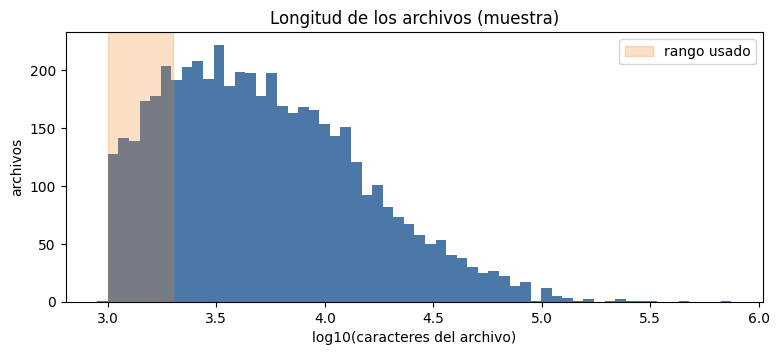

In [4]:
stream = load_dataset(DATASET, split='train', streaming=True)
print('Columnas:', list(stream.features))

muestra = list(stream.take(min(5000, 40 * N_TOTAL)))
longitudes = np.array([len(e['content']) for e in muestra])
en_rango = (longitudes >= MIN_CARACTERES) & (longitudes <= MAX_CARACTERES)

print(f'Muestra: {len(muestra):,} archivos')
print(f'Caracteres por archivo: mediana {np.median(longitudes):,.0f} | p10 {np.percentile(longitudes, 10):,.0f} '
      f'| p90 {np.percentile(longitudes, 90):,.0f} | máximo {longitudes.max():,}')
print(f'En el rango {MIN_CARACTERES}-{MAX_CARACTERES}: {en_rango.mean():.1%}, '
      f'o sea que hay que recorrer unos {N_TOTAL / max(en_rango.mean(), 1e-9):,.0f} archivos para tener {N_TOTAL:,}')

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(np.log10(longitudes), bins=60, color='#4C78A8')
ax.axvspan(np.log10(MIN_CARACTERES), np.log10(MAX_CARACTERES), color='#F58518', alpha=0.25, label='rango usado')
ax.set_xlabel('log10(caracteres del archivo)')
ax.set_ylabel('archivos')
ax.set_title('Longitud de los archivos (muestra)')
ax.legend()
plt.show()

In [5]:
licencias = Counter(e['license'] for e in muestra)
print('Licencias más frecuentes:', ', '.join(f'{k} ({v})' for k, v in licencias.most_common(5)))
print(f"Archivos autogenerados en la muestra: {sum(bool(e['autogenerated']) for e in muestra)}")
print(f"Longitud media de línea: {np.mean([float(e['line_mean']) for e in muestra]):.1f} caracteres")

ejemplo = next(e for e in muestra if MIN_CARACTERES <= len(e['content']) <= MAX_CARACTERES)
print(f"\nEjemplo: {ejemplo['repo_name']}/{ejemplo['path']} ({len(ejemplo['content'])} caracteres)\n")
print('\n'.join(ejemplo['content'].splitlines()[:25]))

Licencias más frecuentes: apache-2.0 (1067), mit (888), gpl-3.0 (872), bsd-3-clause (849), agpl-3.0 (480)
Archivos autogenerados en la muestra: 0
Longitud media de línea: 34.9 caracteres

Ejemplo: pipet/pipet/pipet/sources/zendesk/tasks.py (1544 caracteres)

from contextlib import contextmanager
from datetime import datetime
from inspect import isclass

from celery import chord, group
from celery_once import QueueOnce
from celery.schedules import crontab
from celery.utils.log import get_task_logger
from sqlalchemy.orm.attributes import flag_modified

# from pipet import celery
from pipet.models import db, Organization
from pipet.sources.zendesk import ZendeskAccount
from pipet.sources.zendesk.models import (
    Base,
    CLASS_REGISTRY,
)


logger = get_task_logger(__name__)


# @celery.task(base=QueueOnce, once={'graceful': True})
def sync(account_id):
    with app.app_context():


## 4. Preprocesamiento

Recorremos el stream y nos quedamos con los primeros 8.000 archivos que tienen entre 1.000 y 2.000 caracteres. El corpus filtrado se guarda en disco para que al volver a ejecutar se use exactamente el mismo.

Después tokenizamos con el tokenizador de SmolLM2, que es el mismo para el 135M y el 360M, y agregamos `<|endoftext|>` al final de cada archivo. Para segmentar, concatenamos los archivos y cortamos en bloques de 256 tokens (el sobrante del final se descarta). La segmentación se aplica por separado a cada partición después del split, para que ningún bloque mezcle archivos de entrenamiento con archivos de prueba.

In [6]:
RUTA_CORPUS = os.path.join(DIR_BASE, f'corpus_{N_TOTAL}.json')

if os.path.exists(RUTA_CORPUS):
    with open(RUTA_CORPUS, encoding='utf-8') as f:
        corpus = json.load(f)
    print(f'Corpus cargado de {RUTA_CORPUS}: {len(corpus):,} archivos')
else:
    t0 = time.time()
    revisados, corpus = 0, []
    for ejemplo in load_dataset(DATASET, split='train', streaming=True):
        revisados += 1
        if MIN_CARACTERES <= len(ejemplo['content']) <= MAX_CARACTERES:
            corpus.append(ejemplo['content'])
            if len(corpus) == N_TOTAL:
                break
    with open(RUTA_CORPUS, 'w', encoding='utf-8') as f:
        json.dump(corpus, f)
    print(f'Revisados {revisados:,} archivos, conservados {len(corpus):,} ({time.time() - t0:.0f} s)')

assert len(corpus) == N_TOTAL
assert all(MIN_CARACTERES <= len(c) <= MAX_CARACTERES for c in corpus)

Resolving data files:   0%|          | 0/54 [00:00<?, ?it/s]

Revisados 38,071 archivos, conservados 8,000 (33 s)


config.json:   0%|          | 0.00/704 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.66k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/801k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/831 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.10M [00:00<?, ?B/s]

... (3 outputs left out)

merges.txt:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/831 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.10M [00:00<?, ?B/s]

Vocabulario: 49,152 tokens | fin de texto: '<|endoftext|>' (id 0)
33 caracteres -> ['def', 'Ġsum', 'a', '(', 'a', ',', 'Ġb', '):', 'ĊĠĠĠ', 'Ġreturn', 'Ġa', 'Ġ+', 'Ġb', 'Ċ']

Tokenización: 7.1 s | tokens por archivo: mediana 421, mín 199, máx 1358 | total 3,461,031
Caracteres por token: 3.41


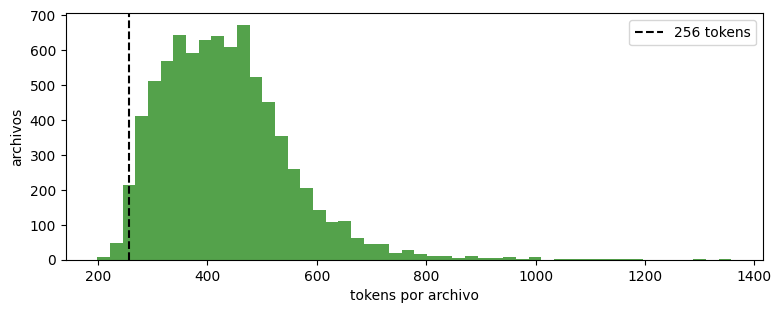

In [7]:
tokenizer = AutoTokenizer.from_pretrained(MODELOS_HF['135M'])
tok_360 = AutoTokenizer.from_pretrained(MODELOS_HF['360M'])
assert tokenizer.get_vocab() == tok_360.get_vocab()
del tok_360

VOCAB = len(tokenizer)
EOS_ID = tokenizer.eos_token_id
print(f'Vocabulario: {VOCAB:,} tokens | fin de texto: {tokenizer.eos_token!r} (id {EOS_ID})')

prueba = 'def suma(a, b):\n    return a + b\n'
print(f'{len(prueba)} caracteres -> {tokenizer.tokenize(prueba)}')

t0 = time.time()
ids_por_archivo = [ids + [EOS_ID] for ids in tokenizer(corpus, add_special_tokens=False)['input_ids']]
tokens_por_archivo = np.array([len(x) for x in ids_por_archivo])
print(f'\nTokenización: {time.time() - t0:.1f} s | tokens por archivo: mediana {np.median(tokens_por_archivo):.0f}, '
      f'mín {tokens_por_archivo.min()}, máx {tokens_por_archivo.max()} | total {tokens_por_archivo.sum():,}')
print(f'Caracteres por token: {sum(map(len, corpus)) / tokens_por_archivo.sum():.2f}')

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(tokens_por_archivo, bins=50, color='#54A24B')
ax.axvline(CONTEXTO, color='k', ls='--', label=f'{CONTEXTO} tokens')
ax.set_xlabel('tokens por archivo')
ax.set_ylabel('archivos')
ax.legend()
plt.show()

In [8]:
def segmentar(lista_ids, contexto=CONTEXTO):
    plano = torch.tensor([t for ids in lista_ids for t in ids], dtype=torch.long)
    n_bloques = len(plano) // contexto
    return plano[:n_bloques * contexto].view(n_bloques, contexto)


demo = segmentar(ids_por_archivo[:3])
print(f'3 archivos ({sum(map(len, ids_por_archivo[:3]))} tokens) -> tensor {tuple(demo.shape)}')
print('Inicio del primer bloque:', repr(tokenizer.decode(demo[0, :30])))

3 archivos (1112 tokens) -> tensor (4, 256)
Inicio del primer bloque: 'from contextlib import contextmanager\nfrom datetime import datetime\nfrom inspect import isclass\n\nfrom celery import chord, group\nfrom celery_once'


## 5. Split train / validación / prueba

Barajamos los 8.000 archivos con semilla fija y los repartimos en 6.400 / 800 / 800. El split se hace por archivo y luego se segmenta cada partición.

In [9]:
orden = np.random.default_rng(SEMILLA).permutation(N_TOTAL)
idx_train, idx_val, idx_test = orden[:N_TRAIN], orden[N_TRAIN:N_TRAIN + N_VAL], orden[N_TRAIN + N_VAL:]
assert len(idx_test) == N_TEST
assert not (set(idx_train) & set(idx_val) or set(idx_train) & set(idx_test) or set(idx_val) & set(idx_test))

ids_train = [ids_por_archivo[i] for i in idx_train]
ids_val = [ids_por_archivo[i] for i in idx_val]
ids_test = [ids_por_archivo[i] for i in idx_test]

bloques_train, bloques_val, bloques_test = segmentar(ids_train), segmentar(ids_val), segmentar(ids_test)

display(pd.DataFrame({
    'archivos': [len(ids_train), len(ids_val), len(ids_test)],
    'tokens': [sum(map(len, x)) for x in (ids_train, ids_val, ids_test)],
    f'bloques de {CONTEXTO}': [len(bloques_train), len(bloques_val), len(bloques_test)],
    'tokens predichos': [b.shape[0] * (CONTEXTO - 1) for b in (bloques_train, bloques_val, bloques_test)],
}, index=['entrenamiento', 'validación', 'prueba']))

,archivos,tokens,bloques de 256,tokens predichos
entrenamiento,6400,2765386,10802,2754510
validación,800,347323,1356,345780
prueba,800,348322,1360,346800


## 6. Modelo desde cero

Implementamos un GPT decoder-only con LayerNorm antes de cada subcapa (pre-LN):

- Embedding de tokens más embedding posicional aprendido (256 posiciones).
- 6 bloques, cada uno con atención multi-cabeza causal (8 cabezas, máscara triangular) y un MLP de 512 a 2048 a 512 con GELU. Ambas subcapas tienen conexión residual y dropout.
- LayerNorm final y una capa de salida que comparte pesos con el embedding de tokens (weight tying). Con un vocabulario de 49.152 esto ahorra unos 25M de parámetros.
- Pesos inicializados con N(0, 0.02); las proyecciones de salida de cada bloque se escalan por 1/√(2·capas), como en GPT-2.

Se entrena con entropía cruzada del siguiente token: de cada bloque de 256 tokens, las posiciones 0 a 254 son la entrada y las posiciones 1 a 255 son el objetivo.

In [10]:
class AtencionCausal(nn.Module):
    def __init__(self, d_modelo, n_cabezas, dropout, contexto):
        super().__init__()
        assert d_modelo % n_cabezas == 0
        self.n_cabezas = n_cabezas
        self.qkv = nn.Linear(d_modelo, 3 * d_modelo)
        self.salida = nn.Linear(d_modelo, d_modelo)
        self.drop_atencion = nn.Dropout(dropout)
        self.drop_residual = nn.Dropout(dropout)
        mascara = torch.tril(torch.ones(contexto, contexto, dtype=torch.bool))
        self.register_buffer('mascara', mascara.view(1, 1, contexto, contexto), persistent=False)

    def forward(self, x):
        B, T, C = x.shape
        d_cabeza = C // self.n_cabezas
        q, k, v = self.qkv(x).split(C, dim=2)
        q, k, v = (t.view(B, T, self.n_cabezas, d_cabeza).transpose(1, 2) for t in (q, k, v))  # (B, h, T, d)
        puntajes = (q @ k.transpose(-2, -1)) / math.sqrt(d_cabeza)
        puntajes = puntajes.masked_fill(~self.mascara[:, :, :T, :T], float('-inf'))
        pesos = self.drop_atencion(F.softmax(puntajes.float(), dim=-1).to(v.dtype))
        y = (pesos @ v).transpose(1, 2).contiguous().view(B, T, C)
        return self.drop_residual(self.salida(y))


class BloqueTransformer(nn.Module):
    def __init__(self, d_modelo, n_cabezas, dropout, contexto):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_modelo)
        self.atencion = AtencionCausal(d_modelo, n_cabezas, dropout, contexto)
        self.ln2 = nn.LayerNorm(d_modelo)
        self.mlp = nn.Sequential(
            nn.Linear(d_modelo, 4 * d_modelo),
            nn.GELU(),
            nn.Linear(4 * d_modelo, d_modelo),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        x = x + self.atencion(self.ln1(x))
        return x + self.mlp(self.ln2(x))


class GPTDesdeCero(nn.Module):
    def __init__(self, vocab, d_modelo, n_capas, n_cabezas, dropout, contexto):
        super().__init__()
        self.contexto = contexto
        self.emb_tokens = nn.Embedding(vocab, d_modelo)
        self.emb_posicion = nn.Embedding(contexto, d_modelo)
        self.drop = nn.Dropout(dropout)
        self.bloques = nn.ModuleList(BloqueTransformer(d_modelo, n_cabezas, dropout, contexto) for _ in range(n_capas))
        self.ln_final = nn.LayerNorm(d_modelo)
        self.cabeza = nn.Linear(d_modelo, vocab, bias=False)
        self.cabeza.weight = self.emb_tokens.weight

        self.apply(self._inicializar)
        for nombre, p in self.named_parameters():
            if nombre.endswith('atencion.salida.weight') or nombre.endswith('mlp.2.weight'):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * n_capas))

    @staticmethod
    def _inicializar(modulo):
        if isinstance(modulo, (nn.Linear, nn.Embedding)):
            nn.init.normal_(modulo.weight, mean=0.0, std=0.02)
        if isinstance(modulo, nn.Linear) and modulo.bias is not None:
            nn.init.zeros_(modulo.bias)

    def forward(self, ids, solo_ultimo=False):
        T = ids.shape[1]
        assert T <= self.contexto
        posiciones = torch.arange(T, device=ids.device)
        x = self.drop(self.emb_tokens(ids) + self.emb_posicion(posiciones))
        for bloque in self.bloques:
            x = bloque(x)
        x = self.ln_final(x)
        if solo_ultimo:
            x = x[:, -1:, :]
        return self.cabeza(x)

Las siguientes funciones sirven para los cinco modelos. `logits_de` y `logits_ultimo` reciben tanto el GPT propio como un modelo de Hugging Face, y así la pérdida, la evaluación, el entrenamiento y la generación son el mismo código para todos.

In [11]:
def es_hf(modelo):
    return not isinstance(modelo, GPTDesdeCero)


def logits_de(modelo, ids):
    if es_hf(modelo):
        return modelo(input_ids=ids, use_cache=False).logits
    return modelo(ids)


def logits_ultimo(modelo, ids):
    # para generar solo se necesita la última posición
    if es_hf(modelo):
        ocultos = modelo.get_decoder()(input_ids=ids, use_cache=False).last_hidden_state[:, -1:, :]
        return modelo.get_output_embeddings()(ocultos)[:, -1, :]
    return modelo(ids, solo_ultimo=True)[:, -1, :]


def perdida_lm(modelo, bloque):
    entrada, objetivo = bloque[:, :-1], bloque[:, 1:]
    with autocast():
        logits = logits_de(modelo, entrada)
    return F.cross_entropy(logits.float().reshape(-1, logits.size(-1)), objetivo.reshape(-1))


@torch.no_grad()
def evaluar_nll(modelo, bloques, batch):
    # NLL promedio por token sobre todos los bloques
    estaba_entrenando = modelo.training
    modelo.eval()
    suma, n = 0.0, 0
    for i in range(0, len(bloques), batch):
        b = bloques[i:i + batch].to(DEVICE)
        with autocast():
            logits = logits_de(modelo, b[:, :-1])
        suma += F.cross_entropy(logits.float().reshape(-1, logits.size(-1)), b[:, 1:].reshape(-1), reduction='sum').item()
        n += b[:, 1:].numel()
    modelo.train(estaba_entrenando)
    return suma / n


def contar_parametros(modelo):
    return sum(p.numel() for p in modelo.parameters())

El ciclo de entrenamiento es el mismo para el GPT y para los finetunings de la sección 7:

- AdamW con β = (0.9, 0.95). El weight decay se aplica solo a las matrices, no a sesgos ni a LayerNorm.
- Warmup lineal durante el 5 % de los pasos y luego decaimiento coseno hasta el 10 % de la tasa máxima.
- Precisión mixta con `torch.autocast`. Con fp16 se usa `GradScaler`, que descarta los pasos con gradiente infinito (los contamos).
- Acumulación de gradiente: cada paso del optimizador usa `micro_batch × accum` secuencias.
- La norma del gradiente se recorta a 1.0.
- Se evalúa en validación varias veces por época y se guarda el mejor estado. Si la pérdida de validación no mejora en `paciencia` evaluaciones seguidas, se detiene el entrenamiento.

In [12]:
def entrenar(modelo, nombre, bloques_tr, bloques_va, *, lr, wd, epocas, micro_batch, accum,
             evals_por_epoca, paciencia, batch_eval, max_pasos=None, betas=(0.9, 0.95), warmup=0.05):
    modelo.to(DEVICE).train()
    decay = [p for p in modelo.parameters() if p.requires_grad and p.dim() >= 2]
    no_decay = [p for p in modelo.parameters() if p.requires_grad and p.dim() < 2]
    optimizador = torch.optim.AdamW([{'params': decay, 'weight_decay': wd}, {'params': no_decay, 'weight_decay': 0.0}],
                                    lr=lr, betas=betas, fused=(DEVICE == 'cuda'))
    pasos_epoca = len(bloques_tr) // (micro_batch * accum)
    if max_pasos:
        pasos_epoca = min(pasos_epoca, max_pasos)
    pasos_totales = pasos_epoca * epocas
    pasos_warmup = max(1, int(warmup * pasos_totales))

    def factor_lr(paso):
        if paso < pasos_warmup:
            return (paso + 1) / pasos_warmup
        avance = (paso - pasos_warmup) / max(1, pasos_totales - pasos_warmup)
        return 0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * min(avance, 1.0)))

    programador = torch.optim.lr_scheduler.LambdaLR(optimizador, factor_lr)
    escalador = torch.amp.GradScaler('cuda', enabled=(AMP_DTYPE == torch.float16))
    eval_cada = max(1, pasos_epoca // evals_por_epoca)

    historia = {'paso': [], 'train': [], 'lr': [], 'val_paso': [], 'val': []}
    val0 = evaluar_nll(modelo, bloques_va, batch_eval)
    historia['val_paso'].append(0)
    historia['val'].append(val0)
    mejor_val, mejor_paso, sin_mejora, descartados = val0, 0, 0, 0
    mejor_estado = {k: v.detach().to('cpu', copy=True) for k, v in modelo.state_dict().items()}
    print(f'[{nombre}] {pasos_totales} pasos ({pasos_epoca} por época, {micro_batch * accum} secuencias por paso) | val inicial {val0:.4f}')

    generador = torch.Generator().manual_seed(SEMILLA)
    paso, t0, detener = 0, time.time(), False
    if DEVICE == 'cuda':
        torch.cuda.reset_peak_memory_stats()
    for epoca in range(1, epocas + 1):
        permutacion = torch.randperm(len(bloques_tr), generator=generador)
        for s in range(pasos_epoca):
            perdida_paso = 0.0
            for m in range(accum):
                inicio = (s * accum + m) * micro_batch
                lote = bloques_tr[permutacion[inicio:inicio + micro_batch]].to(DEVICE, non_blocking=True)
                perdida = perdida_lm(modelo, lote) / accum
                escalador.scale(perdida).backward()
                perdida_paso += perdida.item()
            escalador.unscale_(optimizador)
            norma = nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
            if not torch.isfinite(norma):
                descartados += 1
            escalador.step(optimizador)
            escalador.update()
            optimizador.zero_grad(set_to_none=True)
            programador.step()
            paso += 1
            historia['paso'].append(paso)
            historia['train'].append(perdida_paso)
            historia['lr'].append(programador.get_last_lr()[0])

            if paso % eval_cada == 0 or s == pasos_epoca - 1:
                val = evaluar_nll(modelo, bloques_va, batch_eval)
                historia['val_paso'].append(paso)
                historia['val'].append(val)
                mejora = val < mejor_val
                if mejora:
                    mejor_val, mejor_paso, sin_mejora = val, paso, 0
                    mejor_estado = {k: v.detach().to('cpu', copy=True) for k, v in modelo.state_dict().items()}
                else:
                    sin_mejora += 1
                train_reciente = np.mean(historia['train'][-eval_cada:])
                print(f'  paso {paso:5d} | época {epoca} | train {train_reciente:.4f} | val {val:.4f} (PPL {math.exp(val):7.2f}) '
                      f'| lr {historia["lr"][-1]:.1e} | {time.time() - t0:6.0f} s {"*" if mejora else ""}')
                if paciencia and sin_mejora >= paciencia:
                    print(f'  Se detiene: {paciencia} evaluaciones seguidas sin mejorar')
                    detener = True
                    break
        if detener:
            break

    modelo.load_state_dict(mejor_estado)
    info = {'mejor_paso': mejor_paso, 'mejor_val': mejor_val, 'pasos': paso, 'pasos_planeados': pasos_totales,
            'pasos_por_epoca': pasos_epoca, 'minutos': (time.time() - t0) / 60, 'pasos_descartados': descartados,
            'memoria_gb': torch.cuda.max_memory_allocated() / 2**30 if DEVICE == 'cuda' else None,
            'parada_temprana': detener}
    print(f'[{nombre}] mejor paso {mejor_paso} (val {mejor_val:.4f}, PPL {math.exp(mejor_val):.2f}) | {info["minutos"]:.1f} min'
          + (f' | memoria máx. {info["memoria_gb"]:.1f} GB' if info['memoria_gb'] else '')
          + (f' | pasos descartados por overflow: {descartados}' if descartados else ''))
    return historia, info

In [13]:
fijar_semillas()
gpt = GPTDesdeCero(VOCAB, **CONFIG_GPT).to(DEVICE)
print(f'Parámetros: {contar_parametros(gpt):,} ({gpt.emb_tokens.weight.numel():,} en el embedding compartido con la salida)')

with torch.no_grad():
    perdida0 = perdida_lm(gpt.eval(), bloques_train[:4].to(DEVICE)).item()
print(f'Pérdida inicial {perdida0:.3f}, cercana a ln(vocab) = {math.log(VOCAB):.3f}')

Parámetros: 44,212,224 (25,165,824 en el embedding compartido con la salida)
Pérdida inicial 10.917, cercana a ln(vocab) = 10.803


In [14]:
if os.path.exists(RUTA_GPT) and not REENTRENAR:
    ckpt = torch.load(RUTA_GPT, map_location='cpu')
    gpt = GPTDesdeCero(VOCAB, **ckpt['config']).to(DEVICE)
    gpt.load_state_dict(ckpt['estado'])
    historia_gpt, info_gpt = ckpt['historia'], ckpt['info']
    print(f'Checkpoint cargado de {RUTA_GPT} (mejor val {info_gpt["mejor_val"]:.4f})')
else:
    fijar_semillas()
    gpt = GPTDesdeCero(VOCAB, **CONFIG_GPT)
    historia_gpt, info_gpt = entrenar(gpt, 'GPT desde cero', bloques_train, bloques_val,
                                      batch_eval=BATCH_EVAL['gpt'], **HP_GPT)
    torch.save({'config': CONFIG_GPT, 'estado': gpt.state_dict(), 'historia': historia_gpt, 'info': info_gpt,
                'hiperparametros': HP_GPT}, RUTA_GPT)
    print(f'Checkpoint guardado en {RUTA_GPT}')
gpt = gpt.eval()

[GPT desde cero] 4044 pasos (337 por época, 32 secuencias por paso) | val inicial 10.9076
  paso   168 | época 1 | train 6.6044 | val 4.7909 (PPL  120.41) | lr 6.7e-04 |     50 s *
  paso   336 | época 1 | train 4.3151 | val 3.9402 (PPL   51.43) | lr 8.0e-04 |    105 s *
  paso   337 | época 1 | train 4.3093 | val 3.9369 (PPL   51.26) | lr 8.0e-04 |    110 s *
  paso   504 | época 2 | train 3.7098 | val 3.6147 (PPL   37.14) | lr 7.9e-04 |    163 s *
  paso   672 | época 2 | train 3.4486 | val 3.4090 (PPL   30.24) | lr 7.7e-04 |    217 s *
  paso   674 | época 2 | train 3.4469 | val 3.3977 (PPL   29.89) | lr 7.7e-04 |    223 s *
  paso   840 | época 3 | train 3.1410 | val 3.2685 (PPL   26.27) | lr 7.5e-04 |    277 s *
  paso  1008 | época 3 | train 3.0481 | val 3.1456 (PPL   23.23) | lr 7.2e-04 |    332 s *
  paso  1011 | época 3 | train 3.0428 | val 3.1355 (PPL   23.00) | lr 7.2e-04 |    338 s *
  paso  1176 | época 4 | train 2.7749 | val 3.0497 (PPL   21.11) | lr 6.9e-04 |    391 s *


## 7. Finetuning de los modelos pre-entrenados

Cargamos SmolLM2-135M y SmolLM2-360M con sus pesos y actualizamos todos los parámetros (finetuning completo, sin LoRA). Para que el 360M quepa en los 16 GB de la T4:

- Los pesos y el estado de AdamW quedan en float32, pero el forward y el backward se calculan en precisión mixta.
- Usamos gradient checkpointing: en el backward se recalculan las activaciones en lugar de guardarlas.
- Cada paso acumula 4 lotes de 8 secuencias, es decir 32 secuencias (8.192 tokens).

La tasa de aprendizaje es mucho menor que la del GPT (8e-5 para el 135M y 5e-5 para el 360M) para no dañar lo que los modelos ya aprendieron en el pre-entrenamiento.

In [15]:
def cargar_hf(ruta_o_id):
    modelo = AutoModelForCausalLM.from_pretrained(ruta_o_id)
    return modelo.to(dtype=torch.float32, device=DEVICE)


for clave, id_modelo in MODELOS_HF.items():
    cfg = transformers.AutoConfig.from_pretrained(id_modelo)
    print(f'{id_modelo}: {cfg.num_hidden_layers} capas | dimensión {cfg.hidden_size} | {cfg.num_attention_heads} cabezas '
          f'({cfg.num_key_value_heads} KV) | vocabulario {cfg.vocab_size:,} | embeddings compartidos: {cfg.tie_word_embeddings}')
print(f'GPT desde cero: {CONFIG_GPT["n_capas"]} capas | dimensión {CONFIG_GPT["d_modelo"]} | {CONFIG_GPT["n_cabezas"]} cabezas')

HuggingFaceTB/SmolLM2-135M: 30 capas | dimensión 576 | 9 cabezas (3 KV) | vocabulario 49,152 | embeddings compartidos: True
HuggingFaceTB/SmolLM2-360M: 32 capas | dimensión 960 | 15 cabezas (5 KV) | vocabulario 49,152 | embeddings compartidos: True
GPT desde cero: 6 capas | dimensión 512 | 8 cabezas


In [16]:
def finetunear(clave):
    ruta = RUTAS_FT[clave]
    ruta_historia = os.path.join(ruta, 'historia_entrenamiento.json')
    if os.path.exists(ruta_historia) and not REENTRENAR:
        with open(ruta_historia, encoding='utf-8') as f:
            guardado = json.load(f)
        print(f'SmolLM2-{clave}: se carga el checkpoint de {ruta} (mejor val {guardado["info"]["mejor_val"]:.4f})')
        return guardado['historia'], guardado['info']

    fijar_semillas()
    modelo = cargar_hf(MODELOS_HF[clave])
    print(f'SmolLM2-{clave}: {contar_parametros(modelo):,} parámetros, todos entrenables: '
          f'{all(p.requires_grad for p in modelo.parameters())}')
    modelo.config.use_cache = False
    modelo.gradient_checkpointing_enable(gradient_checkpointing_kwargs={'use_reentrant': False})

    historia, info = entrenar(modelo, f'SmolLM2-{clave}', bloques_train, bloques_val,
                              batch_eval=BATCH_EVAL[clave], **HP_FT[clave])

    modelo.gradient_checkpointing_disable()
    modelo.config.use_cache = True
    modelo.save_pretrained(ruta)
    tokenizer.save_pretrained(ruta)
    with open(ruta_historia, 'w', encoding='utf-8') as f:
        json.dump({'historia': historia, 'info': info, 'hiperparametros': HP_FT[clave]}, f)
    print(f'Checkpoint guardado en {ruta}')
    del modelo
    liberar_memoria()
    return historia, info


historia_135, info_135 = finetunear('135M')

model.safetensors: reconstructing file:   0%|          |  0.00B /  269MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/111 [00:00<?, ?B/s]

SmolLM2-135M: 134,515,008 parámetros, todos entrenables: True
[SmolLM2-135M] 674 pasos (337 por época, 32 secuencias por paso) | val inicial 1.7901
  paso    84 | época 1 | train 1.7085 | val 1.6812 (PPL    5.37) | lr 7.9e-05 |    161 s *
  paso   168 | época 1 | train 1.6475 | val 1.6428 (PPL    5.17) | lr 7.2e-05 |    321 s *
  paso   252 | época 1 | train 1.6040 | val 1.6178 (PPL    5.04) | lr 6.1e-05 |    482 s *
  paso   336 | época 1 | train 1.5733 | val 1.6013 (PPL    4.96) | lr 4.7e-05 |    642 s *
  paso   337 | época 1 | train 1.5722 | val 1.6011 (PPL    4.96) | lr 4.7e-05 |    664 s *
  paso   420 | época 2 | train 1.4617 | val 1.5981 (PPL    4.94) | lr 3.2e-05 |    823 s *
  paso   504 | época 2 | train 1.4588 | val 1.5911 (PPL    4.91) | lr 2.0e-05 |    983 s *
  paso   588 | época 2 | train 1.4479 | val 1.5856 (PPL    4.88) | lr 1.1e-05 |   1142 s *
  paso   672 | época 2 | train 1.4437 | val 1.5837 (PPL    4.87) | lr 8.0e-06 |   1302 s *
  paso   674 | época 2 | train 1.

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Checkpoint guardado en /content/drive/MyDrive/MP2_Equipo21/checkpoints/smollm2_135m_finetuned


In [17]:
historia_360, info_360 = finetunear('360M')

model.safetensors: reconstructing file:   0%|          |  0.00B /  724MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/111 [00:00<?, ?B/s]

SmolLM2-360M: 361,821,120 parámetros, todos entrenables: True
[SmolLM2-360M] 674 pasos (337 por época, 32 secuencias por paso) | val inicial 1.5285
  paso    84 | época 1 | train 1.4618 | val 1.4445 (PPL    4.24) | lr 4.9e-05 |    319 s *
  paso   168 | época 1 | train 1.4153 | val 1.4166 (PPL    4.12) | lr 4.5e-05 |    640 s *
  paso   252 | época 1 | train 1.3790 | val 1.3986 (PPL    4.05) | lr 3.8e-05 |    961 s *
  paso   336 | época 1 | train 1.3538 | val 1.3853 (PPL    4.00) | lr 2.9e-05 |   1282 s *
  paso   337 | época 1 | train 1.3528 | val 1.3852 (PPL    4.00) | lr 2.9e-05 |   1326 s *
  paso   420 | época 2 | train 1.2483 | val 1.3853 (PPL    4.00) | lr 2.0e-05 |   1643 s 
  paso   504 | época 2 | train 1.2437 | val 1.3809 (PPL    3.98) | lr 1.2e-05 |   1964 s *
  paso   588 | época 2 | train 1.2379 | val 1.3768 (PPL    3.96) | lr 7.0e-06 |   2285 s *
  paso   672 | época 2 | train 1.2347 | val 1.3758 (PPL    3.96) | lr 5.0e-06 |   2607 s *
  paso   674 | época 2 | train 1.2

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Checkpoint guardado en /content/drive/MyDrive/MP2_Equipo21/checkpoints/smollm2_360m_finetuned


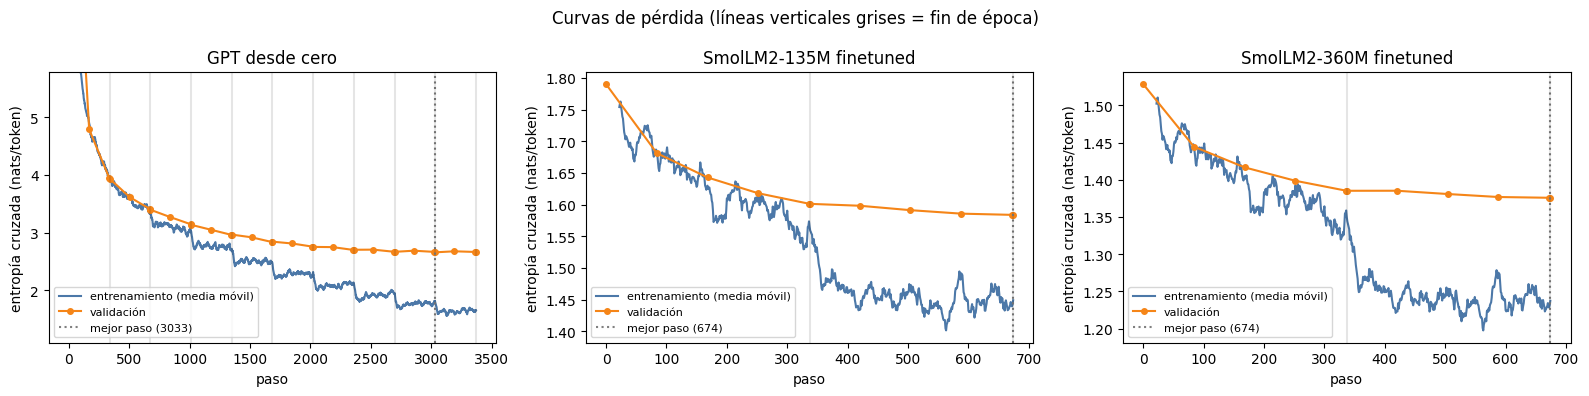

,pasos ejecutados,pasos planeados,mejor paso,val inicial,mejor val,parada temprana,minutos,memoria GB
GPT desde cero,3370,4044,3033,10.9076,2.6575,True,18.9,4.3
SmolLM2-135M finetuned,674,674,674,1.7901,1.5837,False,22.1,3.6
SmolLM2-360M finetuned,674,674,674,1.5285,1.3757,False,44.2,7.1


In [18]:
HISTORIAS = {'GPT desde cero': (historia_gpt, info_gpt),
             'SmolLM2-135M finetuned': (historia_135, info_135),
             'SmolLM2-360M finetuned': (historia_360, info_360)}


def suavizar(valores, ventana=20):
    ventana = max(1, min(ventana, len(valores)))
    return np.convolve(valores, np.ones(ventana) / ventana, mode='valid')


fig, ejes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (nombre, (h, info)) in zip(ejes, HISTORIAS.items()):
    ventana = max(1, info['pasos_por_epoca'] // 15)
    ax.plot(np.array(h['paso'][ventana - 1:]), suavizar(h['train'], ventana), label='entrenamiento (media móvil)', color='#4C78A8')
    ax.plot(h['val_paso'], h['val'], 'o-', label='validación', color='#F58518', ms=4)
    ax.axvline(info['mejor_paso'], color='gray', ls=':', label=f'mejor paso ({info["mejor_paso"]})')
    for e in range(1, info['pasos'] // info['pasos_por_epoca'] + 1):
        ax.axvline(e * info['pasos_por_epoca'], color='k', alpha=0.1)
    ax.set_title(nombre)
    ax.set_xlabel('paso')
    ax.set_ylabel('entropía cruzada (nats/token)')
    if nombre == 'GPT desde cero' and len(h['val']) > 1:
        ax.set_ylim(top=min(h['val'][0], h['val'][1] + 1.0))  # la pérdida inicial (~10.8) aplana la curva
    ax.legend(fontsize=8)
plt.suptitle('Curvas de pérdida (líneas verticales grises = fin de época)')
plt.tight_layout()
plt.show()

display(pd.DataFrame({n: {'pasos ejecutados': i['pasos'], 'pasos planeados': i['pasos_planeados'], 'mejor paso': i['mejor_paso'],
                          'val inicial': round(h['val'][0], 4), 'mejor val': round(i['mejor_val'], 4),
                          'parada temprana': i['parada_temprana'], 'minutos': round(i['minutos'], 1),
                          'memoria GB': round(i['memoria_gb'], 1) if i['memoria_gb'] else None}
                      for n, (h, i) in HISTORIAS.items()}).T)

## 8. Evaluación y comparación

**Perplejidad.** Para cada modelo calculamos la NLL promedio por token sobre todos los bloques de prueba (255 tokens predichos por bloque) y PPL = exp(NLL). Como todos usan el mismo tokenizador y los mismos bloques, los valores son comparables.

**Validez sintáctica.** Escogemos 200 archivos de prueba con semilla fija. Los primeros 64 tokens de cada uno son el prompt y el modelo genera 128 tokens más, con la función de generación de este notebook (temperatura 0.7, top-p 0.95 y la misma semilla para todos los modelos). Si el modelo genera `<|endoftext|>`, el texto se corta ahí; si no, se quita la última línea, que normalmente queda a medias. Luego se revisa con `ast.parse`.

Como el texto queda cortado en un punto arbitrario (por ejemplo, un `def` sin cuerpo o un paréntesis sin cerrar), aplicamos el mismo procedimiento al código real que sigue a cada prompt y lo usamos como referencia. También reportamos el intervalo de confianza de Wilson al 95 %; con 200 muestras es de unos ±7 puntos.

In [19]:
@torch.no_grad()
def generar(modelo, ids_prompt, max_nuevos, temperatura=0.7, top_k=50, top_p=0.95, generador=None):
    # temperatura = 0 -> greedy
    modelo.eval()
    secuencia = ids_prompt.to(DEVICE)
    terminadas = torch.zeros(secuencia.shape[0], dtype=torch.bool, device=DEVICE)
    for _ in range(max_nuevos):
        ventana = secuencia[:, -CONTEXTO:]
        with autocast():
            logits = logits_ultimo(modelo, ventana)
        logits = logits.float()
        if temperatura == 0:
            siguiente = logits.argmax(dim=-1, keepdim=True)
        else:
            logits = logits / temperatura
            if top_k:
                umbral = torch.topk(logits, top_k, dim=-1).values[:, -1:]
                logits = logits.masked_fill(logits < umbral, float('-inf'))
            if top_p < 1.0:
                ordenados, indices = torch.sort(logits, dim=-1, descending=True)
                probs_ordenadas = F.softmax(ordenados, dim=-1)
                acumulada = probs_ordenadas.cumsum(dim=-1)
                fuera = (acumulada - probs_ordenadas) > top_p
                ordenados = ordenados.masked_fill(fuera, float('-inf'))
                logits = torch.full_like(logits, float('-inf')).scatter(-1, indices, ordenados)
            probs = F.softmax(logits, dim=-1)
            siguiente = torch.multinomial(probs, num_samples=1, generator=generador)
        # las secuencias que ya terminaron se siguen rellenando con EOS
        siguiente = torch.where(terminadas.unsqueeze(1), torch.full_like(siguiente, EOS_ID), siguiente)
        secuencia = torch.cat([secuencia, siguiente], dim=1)
        terminadas |= siguiente.squeeze(1) == EOS_ID
        if terminadas.all():
            break
    return secuencia


def texto_para_validar(ids):
    ids = list(ids)
    if EOS_ID in ids:
        return tokenizer.decode(ids[:ids.index(EOS_ID)])
    texto = tokenizer.decode(ids)
    return texto[:texto.rfind('\n') + 1] if '\n' in texto else texto


def es_valido(codigo):
    try:
        ast.parse(codigo)
        return True
    except (SyntaxError, ValueError, MemoryError, RecursionError):
        return False


def wilson(exitos, n, z=1.96):
    if n == 0:
        return 0.0, 0.0
    p = exitos / n
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    margen = z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return max(0.0, centro - margen), min(1.0, centro + margen)


# solo archivos con al menos 64 + 128 tokens, para tener la continuación real
largo_necesario = TOKENS_PROMPT_VALIDEZ + TOKENS_NUEVOS_VALIDEZ
candidatos = [i for i, ids in enumerate(ids_test) if len(ids) - 1 >= largo_necesario]
elegidos = np.random.default_rng(SEMILLA).choice(candidatos, size=min(N_VALIDEZ, len(candidatos)), replace=False)
PROMPTS_VALIDEZ = torch.tensor([ids_test[i][:TOKENS_PROMPT_VALIDEZ] for i in elegidos], dtype=torch.long)
referencia = [es_valido(texto_para_validar(ids_test[i][:largo_necesario])) for i in elegidos]
print(f'{len(elegidos)} prompts de {TOKENS_PROMPT_VALIDEZ} tokens ({len(candidatos)} archivos de prueba tienen el largo suficiente)')
print(f'Referencia (código real cortado igual): {sum(referencia)}/{len(referencia)} = {np.mean(referencia):.1%} válidos')


def validez_sintactica(modelo):
    generador = torch.Generator(device=DEVICE).manual_seed(SEMILLA)
    validos, textos = [], []
    for i in range(0, len(PROMPTS_VALIDEZ), BATCH_GEN):
        salida = generar(modelo, PROMPTS_VALIDEZ[i:i + BATCH_GEN], TOKENS_NUEVOS_VALIDEZ, generador=generador).cpu()
        for fila in salida:
            texto = texto_para_validar(fila.tolist())
            textos.append(texto)
            validos.append(es_valido(texto))
    return validos, textos

200 prompts de 64 tokens (800 archivos de prueba tienen el largo suficiente)
Referencia (código real cortado igual): 132/200 = 66.0% válidos


In [20]:
CONFIGURACIONES = {
    'GPT desde cero': lambda: gpt,
    'SmolLM2-135M pre-entrenado': lambda: cargar_hf(MODELOS_HF['135M']),
    'SmolLM2-135M finetuned': lambda: cargar_hf(RUTAS_FT['135M']),
    'SmolLM2-360M pre-entrenado': lambda: cargar_hf(MODELOS_HF['360M']),
    'SmolLM2-360M finetuned': lambda: cargar_hf(RUTAS_FT['360M']),
}
CLAVE_BATCH = {'GPT desde cero': 'gpt'} | {n: ('135M' if '135M' in n else '360M') for n in CONFIGURACIONES if 'SmolLM2' in n}
RUTA_RESULTADOS = os.path.join(DIR_BASE, 'resultados_prueba.json')

resultados, textos_validez = {}, {}
for nombre, cargar in CONFIGURACIONES.items():
    t0 = time.time()
    modelo = cargar()
    nll = evaluar_nll(modelo, bloques_test, BATCH_EVAL[CLAVE_BATCH[nombre]])
    validos, textos = validez_sintactica(modelo)
    textos_validez[nombre] = textos
    resultados[nombre] = {'parametros': contar_parametros(modelo), 'nll': nll, 'ppl': math.exp(nll),
                          'validos': int(sum(validos)), 'n': len(validos)}
    print(f'{nombre:28s} | NLL {nll:.4f} | PPL {math.exp(nll):8.2f} | válidas {sum(validos)}/{len(validos)} | {time.time() - t0:5.0f} s')
    if modelo is not gpt:
        del modelo
        liberar_memoria()

with open(RUTA_RESULTADOS, 'w', encoding='utf-8') as f:
    json.dump({'resultados': resultados, 'referencia_validos': int(sum(referencia)), 'referencia_n': len(referencia)}, f, indent=2)

GPT desde cero               | NLL 2.6746 | PPL    14.51 | válidas 117/200 |    25 s


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

SmolLM2-135M pre-entrenado   | NLL 1.7554 | PPL     5.79 | válidas 122/200 |   165 s


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

SmolLM2-135M finetuned       | NLL 1.5626 | PPL     4.77 | válidas 136/200 |   168 s


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

SmolLM2-360M pre-entrenado   | NLL 1.4921 | PPL     4.45 | válidas 142/200 |   340 s


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

<unknown>:12: SyntaxWarning: invalid escape sequence '\.'


SmolLM2-360M finetuned       | NLL 1.3546 | PPL     3.88 | válidas 134/200 |   347 s


/tmp/ipykernel_1946/577213690.py:7: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  tabla.loc['Referencia: código real'] = ['-', None, None, int(sum(referencia)), len(referencia), f'{np.mean(referencia):.1%}',


,parametros,nll,ppl,validos,n,% válido,IC 95 %
GPT desde cero,44.2M,2.6746,14.51,117.0,200.0,58.5%,51.6% - 65.1%
SmolLM2-135M pre-entrenado,134.5M,1.7554,5.79,122.0,200.0,61.0%,54.1% - 67.5%
SmolLM2-135M finetuned,134.5M,1.5626,4.77,136.0,200.0,68.0%,61.2% - 74.1%
SmolLM2-360M pre-entrenado,361.8M,1.4921,4.45,142.0,200.0,71.0%,64.4% - 76.8%
SmolLM2-360M finetuned,361.8M,1.3546,3.88,134.0,200.0,67.0%,60.2% - 73.1%
Referencia: código real,-,NaN,NaN,132.0,200.0,66.0%,59.2% - 72.2%


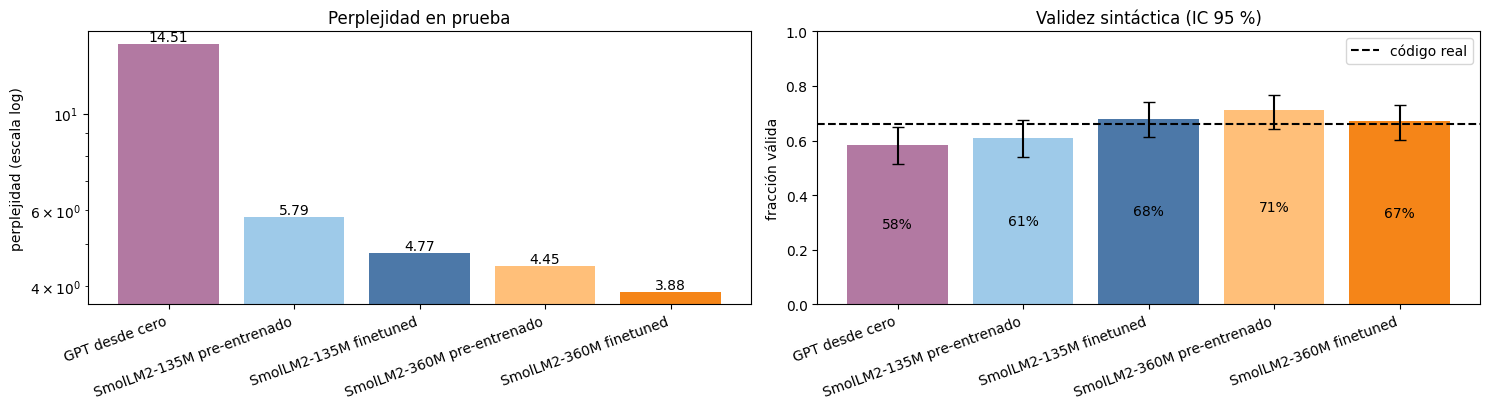

In [21]:
tabla = pd.DataFrame(resultados).T
tabla['parametros'] = tabla['parametros'].astype(int).map(lambda x: f'{x / 1e6:.1f}M')
tabla['% válido'] = [f'{r["validos"] / r["n"]:.1%}' for r in resultados.values()]
tabla['IC 95 %'] = ['{:.1%} - {:.1%}'.format(*wilson(r['validos'], r['n'])) for r in resultados.values()]
tabla['nll'] = tabla['nll'].astype(float).round(4)
tabla['ppl'] = tabla['ppl'].astype(float).round(2)
tabla.loc['Referencia: código real'] = ['-', None, None, int(sum(referencia)), len(referencia), f'{np.mean(referencia):.1%}',
                                         '{:.1%} - {:.1%}'.format(*wilson(sum(referencia), len(referencia)))]
display(tabla[['parametros', 'nll', 'ppl', 'validos', 'n', '% válido', 'IC 95 %']])

nombres = list(resultados)
colores = ['#B279A2', '#9ECAE9', '#4C78A8', '#FFBF79', '#F58518']
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.2))
ppl = [resultados[n]['ppl'] for n in nombres]
barras = ax1.bar(nombres, ppl, color=colores)
ax1.set_yscale('log')
ax1.bar_label(barras, labels=[f'{p:.2f}' for p in ppl])
ax1.set_ylabel('perplejidad (escala log)')
ax1.set_title('Perplejidad en prueba')

prop = [resultados[n]['validos'] / resultados[n]['n'] for n in nombres]
ics = [wilson(resultados[n]['validos'], resultados[n]['n']) for n in nombres]
error = np.array([[p - lo for p, (lo, hi) in zip(prop, ics)], [hi - p for p, (lo, hi) in zip(prop, ics)]])
barras = ax2.bar(nombres, prop, yerr=error, capsize=4, color=colores)
ax2.axhline(np.mean(referencia), color='k', ls='--', label='código real')
ax2.bar_label(barras, labels=[f'{p:.0%}' for p in prop], label_type='center')
ax2.set_ylim(0, 1)
ax2.set_ylabel('fracción válida')
ax2.set_title('Validez sintáctica (IC 95 %)')
ax2.legend()
for ax in (ax1, ax2):
    ax.tick_params(axis='x', rotation=20)
    for etiqueta in ax.get_xticklabels():
        etiqueta.set_horizontalalignment('right')
plt.tight_layout()
plt.show()

### Análisis comparativo

La siguiente celda arma el análisis con los valores obtenidos en esta ejecución.

In [22]:
r = resultados


def cambio(antes, despues):
    return (despues - antes) / antes * 100


def puntos(a, b):
    return (r[b]['validos'] / r[b]['n'] - r[a]['validos'] / r[a]['n']) * 100


def se_traslapan(a, b):
    la, ha = wilson(r[a]['validos'], r[a]['n'])
    lb, hb = wilson(r[b]['validos'], r[b]['n'])
    return la <= hb and lb <= ha


lineas = []
for tam in ('135M', '360M'):
    base, ft = f'SmolLM2-{tam} pre-entrenado', f'SmolLM2-{tam} finetuned'
    c = cambio(r[base]['ppl'], r[ft]['ppl'])
    lineas.append(f'- En el {tam}, el finetuning lleva la perplejidad de {r[base]["ppl"]:.2f} a {r[ft]["ppl"]:.2f} ({c:+.1f} %). '
                  f'La validez pasa de {r[base]["validos"]} a {r[ft]["validos"]} de {r[ft]["n"]} ({puntos(base, ft):+.1f} puntos)'
                  + (', pero los intervalos de confianza se traslapan, así que esa diferencia no es significativa.'
                     if se_traslapan(base, ft) else ', una diferencia mayor que el margen de error.'))
for estado in ('pre-entrenado', 'finetuned'):
    a, b = f'SmolLM2-135M {estado}', f'SmolLM2-360M {estado}'
    lineas.append(f'- Comparando tamaños ({estado}): el 360M tiene PPL {r[b]["ppl"]:.2f} frente a {r[a]["ppl"]:.2f} del 135M '
                  f'({cambio(r[a]["ppl"], r[b]["ppl"]):+.1f} %), y validez {r[b]["validos"]} frente a {r[a]["validos"]} de {r[b]["n"]}.')
p360, f135 = r['SmolLM2-360M pre-entrenado']['ppl'], r['SmolLM2-135M finetuned']['ppl']
if p360 < f135:
    lineas.append(f'- El 360M sin finetuning ({p360:.2f}) ya es mejor que el 135M con finetuning ({f135:.2f}): '
                  'en este caso pesa más el tamaño del modelo que la adaptación al dominio.')
else:
    lineas.append(f'- El 135M con finetuning ({f135:.2f}) supera al 360M sin finetuning ({p360:.2f}): '
                  'la adaptación al dominio compensa la diferencia de tamaño.')
g = r['GPT desde cero']
lineas.append(f'- El GPT desde cero llega a PPL {g["ppl"]:.2f}, {g["ppl"] / r["SmolLM2-135M pre-entrenado"]["ppl"]:.1f} veces la del 135M '
              f'sin finetuning, y {g["validos"]} de {g["n"]} completaciones válidas. Con unos {len(bloques_train) * CONTEXTO / 1e6:.1f}M '
              'tokens de entrenamiento aprende patrones locales (indentación, palabras clave, nombres comunes), mientras que los SmolLM2 '
              'vienen pre-entrenados con billones de tokens.')
lineas.append(f'- El código real, cortado con la misma regla, es válido en el {np.mean(referencia):.0%} de los casos. Una parte importante '
              'de los errores se debe al corte y no al modelo, por eso las conclusiones se basan sobre todo en la perplejidad.')
for nombre, (h, info) in HISTORIAS.items():
    train_final = np.mean(h['train'][-max(1, info['pasos_por_epoca'] // 4):])
    sube = h['val'][-1] > info['mejor_val'] + 1e-4
    lineas.append(f'- {nombre}: la mejor pérdida de validación ({info["mejor_val"]:.4f}) se dio en el paso {info["mejor_paso"]} de {info["pasos"]}, '
                  f'con pérdida de entrenamiento final de {train_final:.4f}. '
                  + ('Después de ese punto la validación empezó a subir (sobreajuste), por eso se guardó el estado de ese paso.' if sube
                     else 'La validación no empeoró hasta el final, así que no se ve sobreajuste en este número de pasos.'))
display(Markdown('\n'.join(lineas)))

- En el 135M, el finetuning lleva la perplejidad de 5.79 a 4.77 (-17.5 %). La validez pasa de 122 a 136 de 200 (+7.0 puntos), pero los intervalos de confianza se traslapan, así que esa diferencia no es significativa.
- En el 360M, el finetuning lleva la perplejidad de 4.45 a 3.88 (-12.8 %). La validez pasa de 142 a 134 de 200 (-4.0 puntos), pero los intervalos de confianza se traslapan, así que esa diferencia no es significativa.
- Comparando tamaños (pre-entrenado): el 360M tiene PPL 4.45 frente a 5.79 del 135M (-23.2 %), y validez 142 frente a 122 de 200.
- Comparando tamaños (finetuned): el 360M tiene PPL 3.88 frente a 4.77 del 135M (-18.8 %), y validez 134 frente a 136 de 200.
- El 360M sin finetuning (4.45) ya es mejor que el 135M con finetuning (4.77): en este caso pesa más el tamaño del modelo que la adaptación al dominio.
- El GPT desde cero llega a PPL 14.51, 2.5 veces la del 135M sin finetuning, y 117 de 200 completaciones válidas. Con unos 2.8M tokens de entrenamiento aprende patrones locales (indentación, palabras clave, nombres comunes), mientras que los SmolLM2 vienen pre-entrenados con billones de tokens.
- El código real, cortado con la misma regla, es válido en el 66% de los casos. Una parte importante de los errores se debe al corte y no al modelo, por eso las conclusiones se basan sobre todo en la perplejidad.
- GPT desde cero: la mejor pérdida de validación (2.6575) se dio en el paso 3033 de 3370, con pérdida de entrenamiento final de 1.6516. Después de ese punto la validación empezó a subir (sobreajuste), por eso se guardó el estado de ese paso.
- SmolLM2-135M finetuned: la mejor pérdida de validación (1.5837) se dio en el paso 674 de 674, con pérdida de entrenamiento final de 1.4454. La validación no empeoró hasta el final, así que no se ve sobreajuste en este número de pasos.
- SmolLM2-360M finetuned: la mejor pérdida de validación (1.3757) se dio en el paso 674 de 674, con pérdida de entrenamiento final de 1.2365. La validación no empeoró hasta el final, así que no se ve sobreajuste en este número de pasos.

## 9. Generación de ejemplos

Para generar usamos la función `generar` de la sección 8. En cada paso toma los logits de la última posición, aplica temperatura, top-k y top-p, muestrea el siguiente token y lo agrega al contexto. No se usa `model.generate()`.

Mostramos tres ejemplos para cada modelo que entrenamos (desde cero, 135M finetuned y 360M finetuned), con los mismos prompts y la misma semilla. Al final agregamos los dos modelos pre-entrenados para comparar.

In [23]:
PROMPTS_EJEMPLO = [
    'def is_prime(n):\n    """Return True if n is a prime number."""\n',
    'import os\n\n\ndef list_python_files(directory):\n    """Return the paths of all .py files under directory."""\n',
    'class Stack(object):\n    """A simple LIFO stack."""\n\n    def __init__(self):\n',
]


def mostrar_ejemplos(nombre, modelo):
    generador = torch.Generator(device=DEVICE).manual_seed(SEMILLA)
    partes = [f'#### {nombre}']
    for k, prompt in enumerate(PROMPTS_EJEMPLO, 1):
        ids = torch.tensor([tokenizer(prompt, add_special_tokens=False)['input_ids']])
        salida = generar(modelo, ids, TOKENS_EJEMPLO, temperatura=0.7, top_p=0.95, generador=generador)[0].tolist()
        texto = tokenizer.decode(salida[:salida.index(EOS_ID)] if EOS_ID in salida else salida)
        valido = 'sí' if es_valido(texto_para_validar(salida)) else 'no'
        partes.append(f'Ejemplo {k} (sintaxis válida: {valido})\n\n```python\n{texto}\n```')
    display(Markdown('\n\n'.join(partes)))


for nombre in ['GPT desde cero', 'SmolLM2-135M finetuned', 'SmolLM2-360M finetuned',
               'SmolLM2-135M pre-entrenado', 'SmolLM2-360M pre-entrenado']:
    modelo = CONFIGURACIONES[nombre]()
    mostrar_ejemplos(nombre, modelo)
    if modelo is not gpt:
        del modelo
        liberar_memoria()

#### GPT desde cero

Ejemplo 1 (sintaxis válida: no)

```python
def is_prime(n):
    """Return True if n is a prime number."""

def is_like(n):
    """Return the number of integers for the sum of integers for the number of integers."""
    return (n, n) - n + n)

def is_like(n):
    """Return the sum of integers if it is an array of integers """
    return (n + n)

def is_like(n):
    """Return the elements in range."""
    return [n, n, n, n, n, n]

def is_like(n):
    """Return the right element in range."""
    return [n, n, n, n, n, n]

def is_like(n):
    """Return the number of range of integers
    """
    return [n, n
```

Ejemplo 2 (sintaxis válida: no)

```python
import os


def list_python_files(directory):
    """Return the paths of all .py files under directory."""

def list_dir(directory):
    """Returns the paths to a directory."""
    os.makedirs(directory)
    return os.path.join(directory, directory)

def copy_files(directory):
    """Returns the directory in the directory structure to directory."""
    return os.path.join(directory, dir)

def copy_files(directory):
    """Returns the directory directory into a directory."""
    return os.path.isfile(directory)

def copy_files(directory):
    """Returns a directory directory to copy directory."""
    return os.path.abspath(directory)

def copy_files(directory):
    """Returns a directory of the directory."""
    if os.path.isfile(directory):
        os.makedirs(
```

Ejemplo 3 (sintaxis válida: no)

```python
class Stack(object):
    """A simple LIFO stack."""

    def __init__(self):

class SDL_PAY_PRIVO1(object):
    """A LIFO_MIN_PRIVO1: A LIFO
    """
    def __init__(self, *args):
        pass

    def get_by_name(self):
        return self.__name__

    def __getitem__(self, key):
        return self.__class__.__name__

    def __getitem__(self, key):
        return self.__class__[key]

    def __contains__(self, key):
        return key in self.__class__(key)

    def __iter__(self, key):
        return key in self.__name__[key]

class Max_2(object):
    """A LIFO file for use in range(10
```

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

#### SmolLM2-135M finetuned

Ejemplo 1 (sintaxis válida: sí)

```python
def is_prime(n):
    """Return True if n is a prime number."""
# pylint: disable=unused-import

    if n == 1:
        return True

    for i in range(2, n + 1):
        if n % i == 0:
            return False

    return True

def main():
    """Test for prime number checking."""
    assert is_prime(10)

if __name__ == "__main__":
    main()

```

Ejemplo 2 (sintaxis válida: sí)

```python
import os


def list_python_files(directory):
    """Return the paths of all .py files under directory."""

```

Ejemplo 3 (sintaxis válida: no)

```python
class Stack(object):
    """A simple LIFO stack."""

    def __init__(self):
	self.top = 0
	self.array = []

class Stack(object):
    """A simple LIFO stack."""

    def __init__(self):
        self.top = 0
        self.array = []

def main():
    """Main function to test the Stack class."""
    stack = Stack()
    stack.push(10)
    stack.push(20)
    stack.push(30)
    stack.push(40)
    stack.push(50)
    stack.push(60)
    stack.push(70)
    stack.push(80)
    stack.push(90)
    stack.push(100)
    stack.push(110)
```

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

#### SmolLM2-360M finetuned

Ejemplo 1 (sintaxis válida: sí)

```python
def is_prime(n):
    """Return True if n is a prime number."""
#    from __future__ import absolute_import
    if n < 2:
        return False
    elif n == 2 or n == 3:
        return True
    elif n % 2 == 0 or n % 3 == 0:
        return False
    else:
        i = 5
        while i * i <= n:
            if n % i == 0 or n % (i + 2) == 0:
                return False
            i = i + 6
    return True

# 23
# 37
# 57
# 87
# 107
# 127
# 147
# 167
# 187
# 
```

Ejemplo 2 (sintaxis válida: sí)

```python
import os


def list_python_files(directory):
    """Return the paths of all .py files under directory."""

def list_python_files(directory, extension=''):
    """Return the paths of all .py files under directory."""

def list_python_files(directory, extension=''):
    """Return the paths of all .py files under directory."""

def get_python_files(directory):
    """Return the paths of all .py files under directory."""

def get_python_files(directory):
    """Return the paths of all .py files under directory."""

def list_python_files_recursive(directory):
    """Return the paths of all .py files under directory."""

def list_python_files_recursive(directory, extension=''):
    """Return the paths of all .py files under directory."""


```

Ejemplo 3 (sintaxis válida: no)

```python
class Stack(object):
    """A simple LIFO stack."""

    def __init__(self):
#
# This method is called when the stack is initialized.
# This is where the actual stack data is stored.
#
def push(value):
    """Add the given value to the top of the stack."""
    pass

def pop():
    """Remove and return the top value of the stack."""
    pass

def is_empty():
    """Return true if the stack is empty."""
    pass

def peek():
    """Return the top value of the stack."""
    pass

#
# This is a simple example of how to use this class.
#
if __name__ == '__main__':
    # This is a simple example of how to use this class.
    s = Stack()

    print "Is the stack empty? ", s
```

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

#### SmolLM2-135M pre-entrenado

Ejemplo 1 (sintaxis válida: sí)

```python
def is_prime(n):
    """Return True if n is a prime number."""
#     return True if n > 1 else False
#     return is_prime(n)

def is_prime_with_1s(n):
    """Return True if n is a prime number."""
    return is_prime(1) and is_prime(2) and is_prime(3) and is_prime(5) and is_prime(7) and is_prime(11) and is_prime(13) and is_prime(17) and is_prime(19) and is_prime(23) and is_prime(29) and is_prime(31) and is_prime(37) and is_prime(41) and is_prime(4
```

Ejemplo 2 (sintaxis válida: sí)

```python
import os


def list_python_files(directory):
    """Return the paths of all .py files under directory."""

def list_python_files(directory, extension):
    """Return the paths of all .py files under directory."""
    files = os.listdir(directory)
    files.sort()
    for file in files:
        file_path = os.path.join(directory, file)
        if extension in file_path:
            os.remove(file_path)

```

Ejemplo 3 (sintaxis válida: no)

```python
class Stack(object):
    """A simple LIFO stack."""

    def __init__(self):
#   All members are private.
        self.stack = []
        self.size = 0
        self.last = 0

    def push(self, item):
        """Push item into stack.

        If item is not empty, pop it off the stack.
        If item is empty, pop the top.
        If item is not empty, pop the top.
        """
        if self.last == len(self.stack):
            self.last = 0
            self.stack.pop()
        else:
            self.stack.append(item)
            self.last = len(self.stack)
        self.size += 1
        return item

    def pop(self):
        """Pop item from stack.

        If item is not empty, pop it off
```

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

#### SmolLM2-360M pre-entrenado

Ejemplo 1 (sintaxis válida: sí)

```python
def is_prime(n):
    """Return True if n is a prime number."""
#    if n < 2:
#        return False
#    for i in range(2, int(n**0.5)+1):
#        if n % i == 0:
#            return False
#    return True
#
#
#def is_prime_factor(n):
#    """Return True if n is a prime number."""
#    if n < 2:
#        return False
#    for i in range(2, int(n**0.5)+1):
#        if n % i == 0:
#            return False
#    return True
#
#
#def prime_factorization(n):
#    """Return a list of prime
```

Ejemplo 2 (sintaxis válida: sí)

```python
import os


def list_python_files(directory):
    """Return the paths of all .py files under directory."""

def list_python_files(directory):
    """Return the paths of all .py files under directory."""

def remove_python_files(directory):
    """Remove all python files from directory."""

def remove_python_files(directory):
    """Remove all python files from directory."""

def list_python_files(directory):
    """Return the paths of all .py files under directory."""

def list_python_files(directory):
    """Return the paths of all .py files under directory."""

def remove_python_files(directory):
    """Remove all python files from directory."""

def remove_python_files(directory):
    """Remove all python files from directory."""

def list_python_files(
```

Ejemplo 3 (sintaxis válida: no)

```python
class Stack(object):
    """A simple LIFO stack."""

    def __init__(self):
	"""Create an empty stack."""
	self.items = []

    def push(self, item):
	"""Add an item to the stack."""
	self.items.append(item)

    def pop(self):
	"""Remove and return the topmost item."""
	return self.items.pop()

    def isEmpty(self):
	"""Return True if the stack is empty, otherwise return False."""
	return len(self.items) == 0

    def peek(self):
	"""Return the topmost item, without removing it."""
	return self.items[-1]

#
# Exercise 1
#

class Queue(object):
    """A simple first-in, first-out (F
```

## 10. Conclusiones

In [24]:
orden_ppl = sorted(resultados, key=lambda n: resultados[n]['ppl'])
mejora_135 = cambio(r['SmolLM2-135M pre-entrenado']['ppl'], r['SmolLM2-135M finetuned']['ppl'])
mejora_360 = cambio(r['SmolLM2-360M pre-entrenado']['ppl'], r['SmolLM2-360M finetuned']['ppl'])
sobreajuste = [n for n, (h, i) in HISTORIAS.items() if h['val'][-1] > i['mejor_val'] + 1e-4]
memoria = (f", y {info_360['memoria_gb']:.1f} GB de memoria de GPU frente a {info_135['memoria_gb']:.1f} GB"
           if info_360['memoria_gb'] and info_135['memoria_gb'] else '')
if sobreajuste:
    texto_sobreajuste = ('Hubo sobreajuste en ' + ', '.join(sobreajuste) + ': la pérdida de validación subió después del mejor punto. '
                         'Como se guarda el mejor estado, el checkpoint final no queda afectado.')
else:
    texto_sobreajuste = 'En ninguna de las curvas la pérdida de validación empeoró antes de terminar.'

conclusiones = f"""
1. El orden por perplejidad en prueba es: {', '.join(f'{n} ({resultados[n]["ppl"]:.2f})' for n in orden_ppl)}. El mejor modelo es el {orden_ppl[0]}.

2. El finetuning completo cambia la perplejidad en {mejora_135:+.1f} % para el 135M y en {mejora_360:+.1f} % para el 360M. El efecto es {'mayor' if abs(mejora_135) > abs(mejora_360) else 'menor'} en el modelo pequeño.

3. La diferencia entre el GPT desde cero (PPL {r['GPT desde cero']['ppl']:.2f}) y los SmolLM2 muestra el peso del pre-entrenamiento. Con pocos millones de tokens, el modelo desde cero aprende la forma del código (indentación, `def`, `import`, `self.`) pero no su lógica, y después de unas pocas líneas lo que genera deja de tener sentido.

4. El 360M es mejor que el 135M antes y después del finetuning, pero cuesta más: {info_360['minutos']:.0f} minutos de entrenamiento frente a {info_135['minutos']:.0f}{memoria}.

5. {texto_sobreajuste} El corpus es pequeño (6.400 archivos), así que repetir épocas sobre los mismos datos aporta cada vez menos, sobre todo en el GPT desde cero.

6. En validez sintáctica las diferencias entre modelos son de pocos puntos y quedan dentro del margen de error con 200 muestras. Además, el código real cortado con la misma regla solo es válido en el {np.mean(referencia):.0%} de los casos, así que esta métrica sirve más como control que para ordenar los modelos.

7. Limitaciones: el contexto es de 256 tokens, menor que la mediana de un archivo (más de 400 tokens), así que los modelos nunca ven un archivo completo. No verificamos si el código de prueba aparece en los datos de pre-entrenamiento de SmolLM2. Usamos una sola semilla por configuración. Y ninguna de las dos métricas dice si el código hace lo que debe; para eso habría que ejecutarlo contra pruebas, como en HumanEval.
"""
display(Markdown(conclusiones))


1. El orden por perplejidad en prueba es: SmolLM2-360M finetuned (3.88), SmolLM2-360M pre-entrenado (4.45), SmolLM2-135M finetuned (4.77), SmolLM2-135M pre-entrenado (5.79), GPT desde cero (14.51). El mejor modelo es el SmolLM2-360M finetuned.

2. El finetuning completo cambia la perplejidad en -17.5 % para el 135M y en -12.8 % para el 360M. El efecto es mayor en el modelo pequeño.

3. La diferencia entre el GPT desde cero (PPL 14.51) y los SmolLM2 muestra el peso del pre-entrenamiento. Con pocos millones de tokens, el modelo desde cero aprende la forma del código (indentación, `def`, `import`, `self.`) pero no su lógica, y después de unas pocas líneas lo que genera deja de tener sentido.

4. El 360M es mejor que el 135M antes y después del finetuning, pero cuesta más: 44 minutos de entrenamiento frente a 22, y 7.1 GB de memoria de GPU frente a 3.6 GB.

5. Hubo sobreajuste en GPT desde cero: la pérdida de validación subió después del mejor punto. Como se guarda el mejor estado, el checkpoint final no queda afectado. El corpus es pequeño (6.400 archivos), así que repetir épocas sobre los mismos datos aporta cada vez menos, sobre todo en el GPT desde cero.

6. En validez sintáctica las diferencias entre modelos son de pocos puntos y quedan dentro del margen de error con 200 muestras. Además, el código real cortado con la misma regla solo es válido en el 66% de los casos, así que esta métrica sirve más como control que para ordenar los modelos.

7. Limitaciones: el contexto es de 256 tokens, menor que la mediana de un archivo (más de 400 tokens), así que los modelos nunca ven un archivo completo. No verificamos si el código de prueba aparece en los datos de pre-entrenamiento de SmolLM2. Usamos una sola semilla por configuración. Y ninguna de las dos métricas dice si el código hace lo que debe; para eso habría que ejecutarlo contra pruebas, como en HumanEval.


### Empaquetado de la entrega

Esta celda crea `MP2_Equipo21_entrega.zip` en Drive con los tres checkpoints (`gpt_desde_cero.pt`, `smollm2_135m_finetuned/` y `smollm2_360m_finetuned/`) y el notebook, si lo encuentra en *Colab Notebooks*. Antes de correrla hay que guardar el notebook para que el zip incluya las salidas.

In [27]:
NOMBRE_NOTEBOOK = 'MP2_Equipo21.ipynb'
carpeta = '/content/entrega' if EN_COLAB else os.path.join(DIR_BASE, 'entrega')
shutil.rmtree(carpeta, ignore_errors=True)
shutil.copytree(DIR_CKPT, os.path.join(carpeta, 'checkpoints'))
rutas_nb = [os.path.join('/content/drive/MyDrive/Colab Notebooks', NOMBRE_NOTEBOOK), NOMBRE_NOTEBOOK]
nb = next((c for c in rutas_nb if os.path.exists(c)), None)
if nb:
    shutil.copy(nb, carpeta)
else:
    print(f'No se encontró {NOMBRE_NOTEBOOK}; hay que agregarlo al zip manualmente')
zip_local = shutil.make_archive(carpeta, 'zip', carpeta)
destino = shutil.copy(zip_local, os.path.join(DIR_BASE, 'MP2_Equipo21_entrega.zip'))
print(f'Zip: {destino} ({os.path.getsize(destino) / 2**30:.2f} GB)')

Zip: /content/drive/MyDrive/MP2_Equipo21/MP2_Equipo21_entrega.zip (1.87 GB)
